# Task 4: Netflix Content Segmentation
**Auspify Technologies – Machine Learning Internship**

Goal: group Netflix titles into meaningful clusters using unsupervised learning (K-Means). There is no target to predict: the algorithm discovers the groups by itself, and our job is to understand what they mean.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
RS = 42
df = pd.read_csv("Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 1. Prepare numerical and categorical features
K-Means works with distances between numbers, so every feature must be numeric and on a comparable scale. The preparation:

| Kind | Features | Treatment |
|---|---|---|
| Numerical | release year, year added, delay between release and addition, movie length (minutes), number of seasons, number of genres | **Standardized** (mean 0, std 1) |
| Categorical | audience rating group, main country (top 10, others grouped) | **One-Hot** encoded |
| Binary | is TV show, genres (multi-hot) | kept as 0/1 |

**Genres are normalized**: words that reveal the type ("TV", "Movies", "Shows"...) are removed, so "Dramas" and "TV Dramas" become the same theme "Dramas". Otherwise the clusters would just separate movies from TV shows. Genres with fewer than 50 titles are dropped because they are too rare to shape a cluster.

In [3]:
data = df.drop_duplicates(subset="title").reset_index(drop=True).copy()

# --- Numerical features ---
d = pd.to_datetime(data["date_added"], format="%m/%d/%Y", errors="coerce")
data["added_year"] = d.dt.year.fillna(d.dt.year.median())
data["years_to_add"] = (data["added_year"] - data["release_year"]).clip(lower=0)

num = data["duration"].str.extract(r"(\d+)")[0].astype(float)
data["is_tv"] = (data["type"] == "TV Show").astype(int)
data["movie_minutes"] = np.where(data["is_tv"] == 0, num, 0.0)
data["n_seasons"] = np.where(data["is_tv"] == 1, num, 0.0)
data[["movie_minutes", "n_seasons"]] = data[["movie_minutes", "n_seasons"]].fillna(0)
data["n_genres"] = data["listed_in"].str.count(",") + 1

# --- Categorical features ---
rating_map = {"TV-Y": "Kids", "TV-G": "Kids", "G": "Kids",
              "TV-Y7": "Older Kids", "TV-Y7-FV": "Older Kids", "TV-PG": "Older Kids", "PG": "Older Kids",
              "TV-14": "Teens", "PG-13": "Teens", "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults"}
data["rating_group"] = data["rating"].map(rating_map).fillna("Unknown")

country = data["country"].fillna("Unknown").str.split(",").str[0].str.strip()
top_countries = country.value_counts().drop("Unknown", errors="ignore").head(10).index
data["country_group"] = np.where(country.isin(top_countries), country, np.where(country == "Unknown", "Unknown", "Other"))

# --- Normalized genres (multi-hot) ---
def normalize_genre(x):
    x = re.sub(r"\b(TV|Movies|Shows|Series|Features)\b", "", x)
    return re.sub(r"\s+", " ", x).strip(" &-")

norm = data["listed_in"].str.split(",").apply(
    lambda xs: sorted({normalize_genre(x.strip()) for x in xs if normalize_genre(x.strip())}))
genres = pd.get_dummies(norm.explode()).groupby(level=0).max().astype(int)
MIN_GENRE = 50
genres = genres.loc[:, genres.sum() >= MIN_GENRE]
genres.columns = [f"genre_{c}" for c in genres.columns]
GENRES = list(genres.columns)
data = pd.concat([data, genres], axis=1)

NUM = ["release_year", "added_year", "years_to_add", "movie_minutes", "n_seasons", "n_genres"]
CAT = ["rating_group", "country_group"]
BIN = ["is_tv"] + GENRES

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ("bin", "passthrough", BIN),
], sparse_threshold=0)
X = prep.fit_transform(data[NUM + CAT + BIN])
print("Titles:", X.shape[0], "| Features after encoding:", X.shape[1], "| Genre themes kept:", len(GENRES))

Titles: 8787 | Features after encoding: 53 | Genre themes kept: 30


## 2. Apply clustering algorithms (K-Means)
K-Means needs the number of clusters **k** in advance. We try k = 2 to 10 and use two standard tools:
- **Elbow method (inertia)**: how tightly points sit around their cluster centre. It always decreases with k; we look for the "elbow" where gains slow down.
- **Silhouette score** (between -1 and 1): how well each title fits its own cluster compared with the nearest other one. Higher is better.

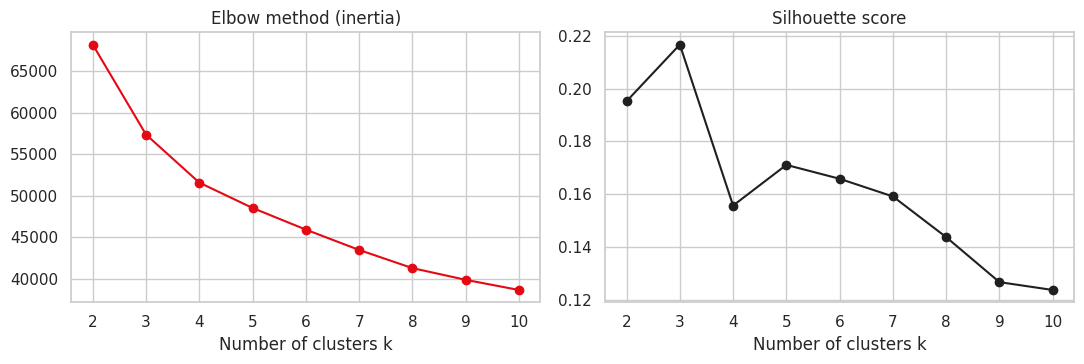

,inertia,silhouette
k,,
2,68183.739,0.195
3,57353.714,0.217
4,51567.368,0.156
5,48517.303,0.171
6,45910.302,0.166
7,43462.330,0.159
8,41277.139,0.144
9,39865.166,0.127
10,38641.595,0.124


In [4]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=3000, random_state=RS)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
scores["inertia"].plot(marker="o", ax=axes[0], color="#e50914"); axes[0].set_title("Elbow method (inertia)")
scores["silhouette"].plot(marker="o", ax=axes[1], color="#221f1f"); axes[1].set_title("Silhouette score")
for a in axes: a.set_xlabel("Number of clusters k")
plt.tight_layout(); plt.show()
scores.round(3)

The silhouette score is highest at the smallest values of k, and on this catalogue the best value (k = 3) simply separates **TV shows**, **movies** and **older classic movies**. That is correct but too coarse to be useful. We therefore keep the silhouette-optimal value for reference but **choose k = 5**, which gives five distinct and readable content groups at a modest cost in silhouette score.

In [5]:
K_best_silhouette = int(scores.loc[3:8, "silhouette"].idxmax())
print("Best silhouette between k=3 and k=8:", K_best_silhouette, "(very coarse split)")
K = 5   # chosen for interpretability; set K = K_best_silhouette to use the statistical optimum
print("Chosen number of clusters:", K)

km = KMeans(n_clusters=K, n_init=20, random_state=RS).fit(X)
data["cluster"] = km.labels_
print("Silhouette score:", round(silhouette_score(X, km.labels_, sample_size=3000, random_state=RS), 3))

Best silhouette between k=3 and k=8: 3 (very coarse split)
Chosen number of clusters: 5
Silhouette score: 0.171


## 3. Identify content groups
For each cluster we compute a profile: its size, the share of TV shows, typical length, typical release year, most common audience rating and country, and the genres that are most characteristic of it.

In [6]:
size = data["cluster"].value_counts().sort_index().rename("titles")
prof = pd.DataFrame({"titles": size, "share (%)": (size / len(data) * 100).round(1)})
prof["TV show (%)"] = (data.groupby("cluster")["is_tv"].mean() * 100).round(1)
prof["median movie length (min)"] = data[data["is_tv"] == 0].groupby("cluster")["movie_minutes"].median()
prof["mean seasons (TV)"] = data[data["is_tv"] == 1].groupby("cluster")["n_seasons"].mean().round(2)
prof["median release year"] = data.groupby("cluster")["release_year"].median()
prof["top rating group"] = pd.crosstab(data["cluster"], data["rating_group"]).idxmax(axis=1)
prof["top country"] = pd.crosstab(data["cluster"], data["country_group"]).idxmax(axis=1)
prof

,titles,share (%),TV show (%),median movie length (min),mean seasons (TV),median release year,top rating group,top country
cluster,,,,,,,,
0,456,5.2,100.0,NaN,4.30,2018.0,Adults,United States
1,3331,37.9,0.0,106.0,NaN,2017.0,Adults,Other
2,611,7.0,4.6,108.0,1.54,1992.0,Teens,United States
3,2517,28.6,12.7,87.0,1.03,2017.0,Adults,United States
4,1872,21.3,99.3,19.0,1.25,2018.0,Adults,Other


In [7]:
# Characteristic genres: share inside the cluster, and "lift" = share in cluster / share overall
share = data.groupby("cluster")[GENRES].mean()
overall = data[GENRES].mean()
lift = share / overall

def top_genres(c, n=4):
    # genres that are frequent in the cluster AND over-represented compared with the whole catalogue
    s = (share.loc[c] * lift.loc[c]).sort_values(ascending=False).head(n).index
    return [g.replace("genre_", "") for g in s]

cluster_names = {}
for c in range(K):
    tg = top_genres(c)
    kind = "TV shows" if prof.loc[c, "TV show (%)"] >= 60 else ("Movies" if prof.loc[c, "TV show (%)"] <= 40 else "Mixed")
    cluster_names[c] = f"{kind}: " + " / ".join(tg[:2])
    print(f"Cluster {c} ({prof.loc[c, 'titles']} titles) -> {cluster_names[c]}")
    print("   characteristic genres:", ", ".join(tg))

Cluster 0 (456 titles) -> TV shows: Kids' / Reality
   characteristic genres: Kids', Reality, Comedies, Crime
Cluster 1 (3331 titles) -> Movies: International / Dramas
   characteristic genres: International, Dramas, Comedies, Independent
Cluster 2 (611 titles) -> Movies: Classic / Cult
   characteristic genres: Classic, Cult, Action & Adventure, Dramas
Cluster 3 (2517 titles) -> Movies: Documentaries / Stand-Up Comedy
   characteristic genres: Documentaries, Stand-Up Comedy, Children & Family, Comedies
Cluster 4 (1872 titles) -> TV shows: International / Crime
   characteristic genres: International, Crime, Docuseries, British


## 4. Visualize clusters
The data has dozens of dimensions, which cannot be drawn. PCA (Principal Component Analysis) compresses them into 2 axes that keep as much information as possible, so we can see the clusters on a plane. Points that look mixed on the plane may still be well separated in the full space, since 2 axes only show part of the variation.

Variance explained by the 2 axes: [24.8 16.5] %


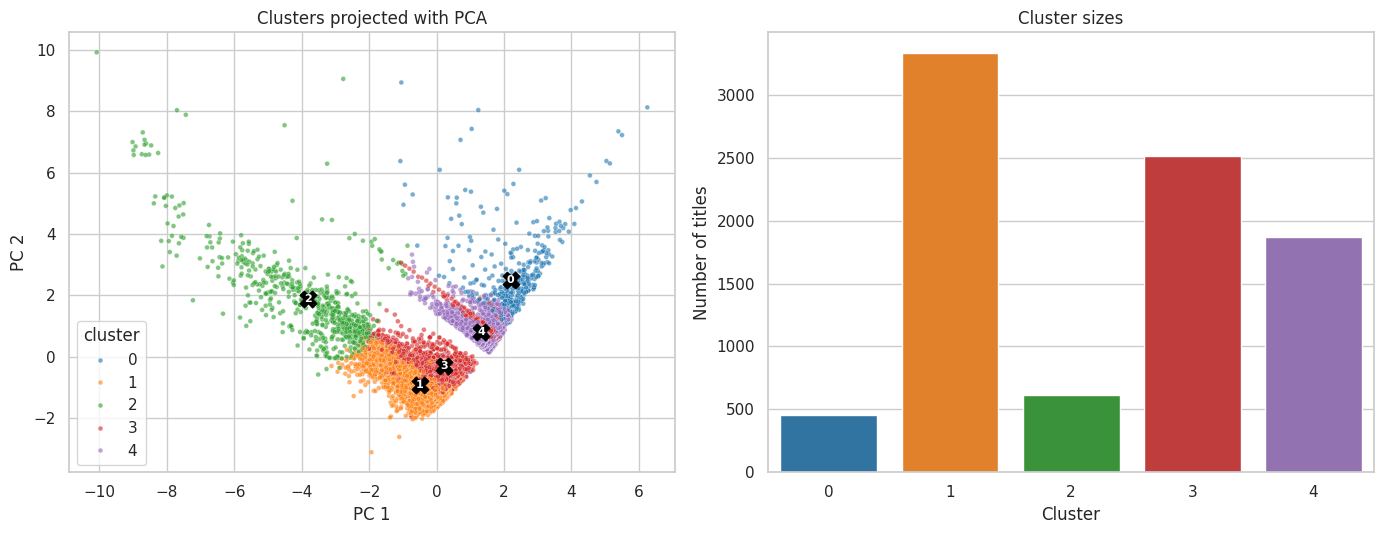

In [8]:
pca = PCA(n_components=2, random_state=RS)
Z = pca.fit_transform(X)
centers = pca.transform(km.cluster_centers_)
print("Variance explained by the 2 axes:", (pca.explained_variance_ratio_ * 100).round(1), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=data["cluster"], palette="tab10", s=12, alpha=.6, ax=axes[0], legend="full")
axes[0].scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=140, label="centroids")
for c, (x, y) in enumerate(centers):
    axes[0].annotate(str(c), (x, y), color="white", ha="center", va="center", fontsize=8, fontweight="bold")
axes[0].set_title("Clusters projected with PCA"); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")

sns.barplot(x=prof.index, y=prof["titles"], hue=prof.index, palette="tab10", legend=False, ax=axes[1])
axes[1].set_title("Cluster sizes"); axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Number of titles")
plt.tight_layout(); plt.show()

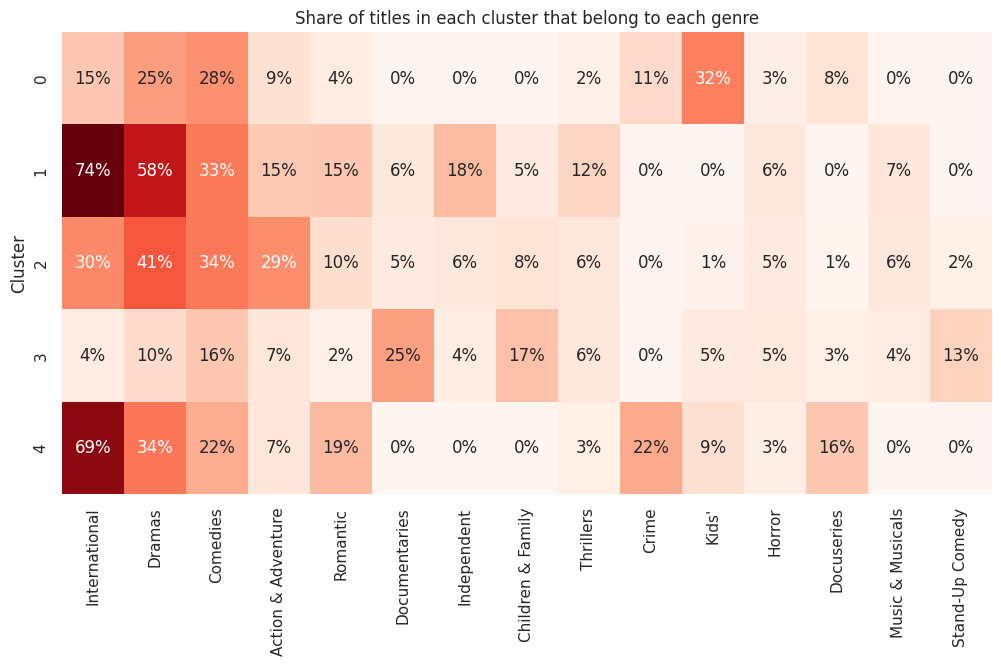

In [9]:
# Genre prevalence per cluster (top 15 genres of the catalogue)
top15 = overall.sort_values(ascending=False).head(15).index
hm = share[top15].copy()
hm.columns = [c.replace("genre_", "") for c in hm.columns]
plt.figure(figsize=(12, 0.7 * K + 2.5))
sns.heatmap(hm, annot=True, fmt=".0%", cmap="Reds", cbar=False)
plt.title("Share of titles in each cluster that belong to each genre"); plt.ylabel("Cluster"); plt.show()

## 5. Interpretation of  cluster characteristics
First, how does each cluster differ from the average title on the numerical features? We use **z-scores**: 0 means "average", +1 means "one standard deviation above the catalogue average", -1 means below.

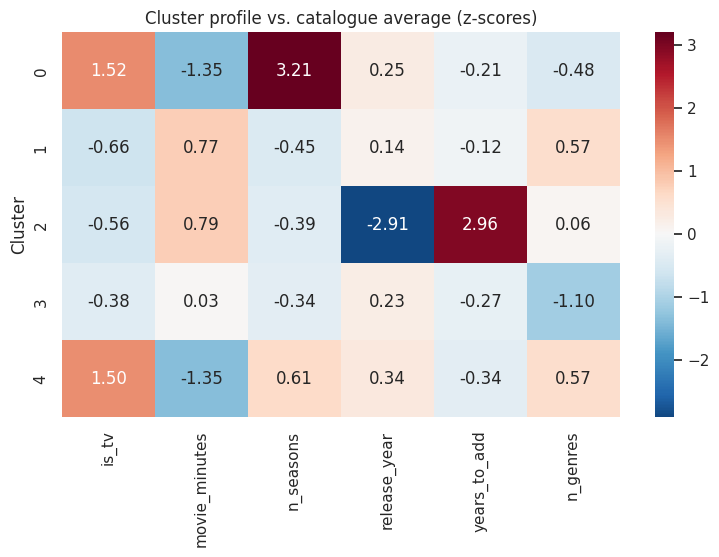

In [9]:
cols = ["is_tv", "movie_minutes", "n_seasons", "release_year", "years_to_add", "n_genres"]
z = (data.groupby("cluster")[cols].mean() - data[cols].mean()) / data[cols].std()
plt.figure(figsize=(9, 0.6 * K + 2))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profile vs. catalogue average (z-scores)"); plt.ylabel("Cluster"); plt.show()

In [10]:
# Representative titles: the 5 titles closest to each cluster centre
dist = km.transform(X)                       # distance of every title to every centroid
for c in range(K):
    idx = np.argsort(dist[:, c])
    idx = [i for i in idx if data.loc[i, "cluster"] == c][:5]
    print(f"Cluster {c} ({cluster_names[c]}):")
    print("   ", " | ".join(data.loc[idx, "title"].astype(str)))

Cluster 0 (TV shows: Kids' / Reality):
    Eastsiders | Harvey Street Kids | The Boss Baby: Back in Business | Girlfriends' Guide to Divorce | Alexa & Katie
Cluster 1 (Movies: International / Dramas):
    The Third Party | All of You | Potato Potahto | Love Off the Cuff | Everything About Her
Cluster 2 (Movies: Classic / Cult):
    Hamburger Hill | School Daze | Rocky V | 300 Miles to Heaven | Total Recall
Cluster 3 (Movies: Documentaries / Stand-Up Comedy):
    Maddman: The Steve Madden Story | 14 Minutes from Earth | 42 Grams | Roll Red Roll | The Bill Murray Stories: Life Lessons Learned From a Mythical Man
Cluster 4 (TV shows: International / Crime):
    Crazy, Lovely, Cool | Tayee | A Taiwanese Tale of Two Cities | Holiday Secrets | Dollar


### Are the clusters stable?
A good segmentation should not change much if we restart K-Means with a different random seed. We measure this with the **Adjusted Rand Index** (1 = identical groupings, 0 = random agreement).

In [11]:
aris = []
for seed in range(5):
    other = KMeans(n_clusters=K, n_init=10, random_state=seed).fit(X).labels_
    aris.append(adjusted_rand_score(data["cluster"], other))
print("Adjusted Rand Index vs. other seeds:", np.round(aris, 3), "| mean:", round(float(np.mean(aris)), 3))

data[["title", "type", "cluster"]].assign(cluster_name=data["cluster"].map(cluster_names)).to_csv("netflix_clusters.csv", index=False)
print("Saved: netflix_clusters.csv")

Adjusted Rand Index vs. other seeds: [0.969 0.945 0.783 0.779 0.783] | mean: 0.852
Saved: netflix_clusters.csv


## Conclusion
- **Approach:** K-Means groups titles by similarity of their features, with no labels. Features were prepared by standardizing numerical columns and One-Hot / multi-hot encoding the categorical ones, so that no single feature dominates the distances.
- **Choosing k:** the elbow and silhouette plots guided the number of clusters. The silhouette optimum is a very coarse split, so k = 5 was chosen as a trade-off between statistical quality and clusters that are readable and distinct.
- **Content groups:** each cluster is described by its share of TV shows, typical length, release period, audience rating, country and, above all, its characteristic genres (see the profile table, the genre heatmap and the z-score heatmap). The automatic names in Step 3 are only a starting point: rename each cluster in your own words after reading its profile.
- **Reliability:** the Adjusted Rand Index above shows how stable the segmentation is. A value close to 1 means the groups are real structure in the data, not an accident of the random start.
- **Limitations:** K-Means assumes roughly round clusters of similar size and is sensitive to the scaling and weighting of features (many 0/1 genre columns weigh a lot against a few numerical ones).
